# 11 Shots and error bars

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bsc-wdc/qdislib/blob/main/notebooks/11_shots_and_errors.ipynb) [![Open in Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/bsc-wdc/qdislib/main?labpath=notebooks/11_shots_and_errors.ipynb)

A cut multiplies the shots a given precision needs. This notebook covers the tools for that: `error=` for a standard error on any result, `total_shots=` to spend one budget well,
`num_samples=` for cuts with too many configurations to list, and `shots_for` for the worst case.

In [1]:
# Installs Qdislib on Colab or Binder; does nothing where Qdislib 2 is installed.
try:
    import Qdislib
    assert Qdislib.__version__.startswith("2.")
except (ImportError, AssertionError):
    %pip install -q "qdislib[qiskit]>=2.0"

In [2]:
# Display helper, not part of Qdislib: renders one figure per value now, and shows them
# under a slider that works without a running kernel (so also on the documentation pages).
import base64, hashlib, io
from IPython.display import display
import matplotlib.pyplot as plt


def slider(render, values, label, start=0):
    frames = []
    for value in values:
        fig = render(value)
        buffer = io.BytesIO()
        fig.savefig(buffer, format="png", dpi=90, bbox_inches="tight")
        plt.close(fig)
        frames.append(base64.b64encode(buffer.getvalue()).decode())
    uid = "s" + hashlib.sha1((label + str(values)).encode()).hexdigest()[:10]
    html = f"""
    <div id="{uid}">
      <label>{label}: <b class="value">{values[start]}</b></label><br>
      <input type="range" min="0" max="{len(values) - 1}" value="{start}" style="width: min(100%, 420px)"><br>
      <img style="max-width: 100%" src="data:image/png;base64,{frames[start]}">
    </div>
    <script>(function () {{
      const root = document.getElementById("{uid}");
      const values = {[str(value) for value in values]};
      const frames = {frames};
      root.querySelector("input").addEventListener("input", function (event) {{
        const i = Number(event.target.value);
        root.querySelector(".value").textContent = values[i];
        root.querySelector("img").src = "data:image/png;base64," + frames[i];
      }});
    }})();</script>"""
    # The PNG is what static viewers without scripts (PDF, GitHub) show.
    display({"text/html": html, "image/png": frames[start]}, raw=True)

In [3]:
%matplotlib inline
import numpy as np
from qiskit import QuantumCircuit
import Qdislib as qd


def example_circuit():
    """Six qubits in a line."""
    qc = QuantumCircuit(6)
    for q, angle in enumerate([0.8, 0.5, 0.6, 0.4, 0.3, 0.7]):
        qc.ry(angle, q)
    for q in range(5):
        qc.cz(q, q + 1)
    for q, angle in enumerate([0.2, 0.1, 0.7, 0.3, 0.9, 0.4]):
        qc.rx(angle, q)
    return qc


circuit = example_circuit()
cut = ["CZ_9"]
exact = qd.analytical_solution(circuit, "Z" * 6)
print(f"exact {exact:+.4f}", qd.cutting_overhead(circuit, cut))

exact +0.1931 {'subcircuits': 12, 'configurations': 6, 'fragments': 2, 'gamma': 3.0}


## `error=True`

Every expectation-value function returns an `Estimate` with `error=True`: a `float`, so old code keeps working, that also has `.error` and `.shots`. The standard error comes from a bootstrap over the shots: each fragment circuit's counts are resampled and the
cheap reconstruction repeated, so it takes classical time and no device time. `error=500` sets the number of resamples (200 by default). An exact run has `error` 0.

In [4]:
value = qd.gate_cutting(circuit, cut, shots=4000, seed=1, error=True)
print(value, "| float:", float(value), "| .error:", round(value.error, 5), "| .shots:", value.shots)
print("exact run:", qd.gate_cutting(circuit, cut, shots=None, error=True))

0.189228 ± 0.0093 | float: 0.18922849999999994 | .error: 0.00931 | .shots: 48000
exact run: 0.19308 ± 0


## Does it match reality?

Repeat the run many times and measure the spread. The bootstrap should match it, within its own noise. The slider shows the same comparison across the number of shots; both fall as `1/sqrt(shots)`.

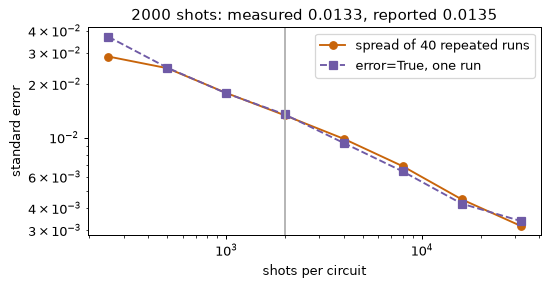

In [5]:
def repeated(shots, repeats=40):
    values = [qd.gate_cutting(circuit, cut, shots=shots, seed=1000 + i) for i in range(repeats)]
    return float(np.std(values, ddof=1))


budget = [250, 500, 1000, 2000, 4000, 8000, 16000, 32000]
measured = [repeated(s) for s in budget]
reported = [qd.gate_cutting(circuit, cut, shots=s, seed=1, error=True).error for s in budget]


def render(shots):
    i = budget.index(shots)
    fig, ax = plt.subplots(figsize=(6.5, 3))
    ax.loglog(budget, measured, "o-", color="#c8640a", label="spread of 40 repeated runs")
    ax.loglog(budget, reported, "s--", color="#6f5aa6", label="error=True, one run")
    ax.axvline(shots, color="0.7")
    ax.set_xlabel("shots per circuit")
    ax.set_ylabel("standard error")
    ax.set_title(f"{shots} shots: measured {measured[i]:.4f}, reported {reported[i]:.4f}")
    ax.legend()
    return fig


slider(render, budget, "shots per circuit", start=3)

With a kernel (Colab, Binder, local) the next cell gives sliders that **run the cut again** for each position, here over the cut gate's angle as well. A static page has no kernel, so nothing appears under it.
It needs `ipywidgets`, which Colab has; elsewhere `pip install ipywidgets`.

In [6]:
from ipywidgets import FloatLogSlider, FloatSlider, interact


def live(shots=4000, angle=1.0):
    qc = QuantumCircuit(4)
    qc.ry(0.7, range(4))
    qc.cz(0, 1)
    qc.cz(2, 3)
    qc.rzz(angle, 1, 2)
    qc.ry(0.3, range(4))
    value = qd.gate_cutting(qc, ["RZZ_7"], "ZZZZ", shots=int(shots), error=True)
    gamma = qd.cutting_overhead(qc, {"gate": ["RZZ_7"]})["gamma"]
    print(f"{value}   exact {qd.analytical_solution(qc, 'ZZZZ'):+.4f}   gamma {gamma:.3f}")


interact(
    live,
    shots=FloatLogSlider(value=4000, base=10, min=2, max=6, step=0.25),
    angle=FloatSlider(value=1.0, min=0.0, max=1.57, step=0.05),
);

Error bars work for distributions too (notebook 06), and for `qd.result_from_counts` results read with `subs.reconstruct`.

## `total_shots=`: one budget

By default each fragment circuit gets `shots`. `total_shots=` spends one budget over all of them instead, in two rounds: a pilot of 20% split by each circuit's weight in the reconstruction, then the rest by weight times the spread the pilot measured (Neyman allocation). Identical circuits share theirs. Here the two runs use the same number of shots:

In [7]:
shots = 4000
circuits = qd.cutting_overhead(circuit, cut)["subcircuits"]


def spread(run, repeats=40):
    values = [run(seed=2000 + i) for i in range(repeats)]
    return float(np.std(values, ddof=1)), float(np.mean(values))


even, even_mean = spread(lambda seed: qd.gate_cutting(circuit, cut, shots=shots, seed=seed))
split, split_mean = spread(lambda seed: qd.gate_cutting(circuit, cut, total_shots=shots * circuits, seed=seed))
print(f"budget {shots * circuits} shots over {circuits} circuits")
print(f"even split:   spread {even:.5f}   mean of the runs {even_mean:+.4f}")
print(f"total_shots=: spread {split:.5f}   mean of the runs {split_mean:+.4f}")
print(f"exact:                         {exact:+.4f}")
print(f"shots an even split would need for the same spread: x{(even / split) ** 2:.2f}")

budget 48000 shots over 12 circuits
even split:   spread 0.00960   mean of the runs +0.1939
total_shots=: spread 0.00819   mean of the runs +0.1937
exact:                         +0.1931
shots an even split would need for the same spread: x1.38


The changelog reports `1.4-1.9x` fewer shots for the same accuracy in Qdislib's tests; the factor depends on the circuit and observable, and the number above comes from this circuit. Under PyCOMPSs the master waits for the pilot round to decide the second one.

## `num_samples=`: too many configurations to list

A cut is a weighted sum over configurations: `6**n` for `n` gate cuts, `8**n` for `n` wire cuts. With `num_samples=N`, Qdislib allocates `N` draws in proportion to `abs(weight) / gamma`, and runs only the circuits the draws use, with `shots` per draw. It is unbiased. It is the way to run a cut whose configurations cannot be listed.

The error has two parts. Which configurations are drawn contributes up to `gamma / sqrt(N)`, whatever the shots. So when configurations do not all fit in `N`, use **more draws with fewer shots each**: `shots=1` is fine.

In [8]:
twelve = QuantumCircuit(12)
twelve.ry(0.5, range(12))
for q in range(11):
    twelve.cz(q, q + 1)
twelve.rx(0.4, range(12))
names = [f"CZ_{12 + q + 1}" for q in (1, 3, 5, 7, 9)]
cost = qd.cutting_overhead(twelve, names)
print(names, cost)

reference = qd.circuit_cutting(twelve, names, "Z" * 12, shots=None)
print(f"exact, by contraction {reference:+.5f}")
for draws in (1000, 10_000, 100_000):
    values = [qd.gate_cutting(twelve, names, "Z" * 12, shots=1, num_samples=draws, seed=s) for s in range(10)]
    print(f"{draws:7d} draws: mean of 10 runs {np.mean(values):+.4f}, spread {np.std(values, ddof=1):.4f}, "
          f"bound gamma/sqrt(N) {cost['gamma'] / np.sqrt(draws):.3f}")
print(qd.gate_cutting(twelve, names, "Z" * 12, shots=1, num_samples=1000, seed=1, error=50))

['CZ_14', 'CZ_16', 'CZ_18', 'CZ_20', 'CZ_22'] {'subcircuits': 46656, 'configurations': 7776, 'fragments': 6, 'gamma': 243.0}


exact, by contraction +0.14845


   1000 draws: mean of 10 runs -0.0092, spread 1.5737, bound gamma/sqrt(N) 7.684


  10000 draws: mean of 10 runs +0.1445, spread 0.0132, bound gamma/sqrt(N) 2.430


 100000 draws: mean of 10 runs +0.1454, spread 0.0036, bound gamma/sqrt(N) 0.768


0.60602 ± 1.3


With this many cuts, `shots=None` still reconstructs exactly here because the fragments are small, which is how the reference above is known. `error=` also works with draws, though it takes longer as `num_samples` grows, so use it with a small `error=` count at large `N`.

In the three-step form each subcircuit's `draws` says how many draws use it, to size its shots: `qd.expectation_value(s, shots=s.draws)`.

## `shots_for`: the worst case

`qd.shots_for(circuit, cuts, epsilon, delta=0.05)` is the shots that guarantee an error below `epsilon` with probability `1 - delta`, for *any* circuit with this cut: Hoeffding's `2 gamma**2 / epsilon**2 * ln(2/delta)`. It is usually far more than `error=True` shows a run needs, so use it as an upper bound and use the bars to decide.

In [9]:
print("worst case for epsilon 0.01:", qd.shots_for(circuit, cut, 0.01), "shots")
value = qd.gate_cutting(circuit, cut, total_shots=48_000, seed=1, error=True)
print(f"a run of 48000 shots: {value}, exact {exact:+.4f}")

worst case for epsilon 0.01: 663999 shots


a run of 48000 shots: 0.1958 ± 0.0091, exact +0.1931


Next: **12 Circuits with free parameters**.